In [46]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [47]:
clean_master_path = r"C:\Users\Aamir Bin Abbas\Desktop\Research & Thesis\Nepal Disaster\CLEANED_NEPAL_FLOOD_DATA\CLEAN_MASTER_DATA_FILE.csv"

df = pd.read_csv(clean_master_path)

In [48]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nData types:")
print(df.dtypes.value_counts())

print("\nMemory usage:")
print(df.memory_usage(deep=True).sum() / (1024 ** 2), "MB")

Rows: 11302
Columns: 101

Data types:
str    101
Name: count, dtype: int64

Memory usage:
25.576269149780273 MB


In [49]:
missing_values = ['Unspecified','Not Provided','Not Available','Not Applicable','not provided']

df_mod = df.replace(
    missing_values,
    np.nan
)

In [50]:
# dropping columns which are compactly empty
for col in df_mod.columns:
    if df_mod[col].isna().all():
        df_mod.drop(columns=col,inplace=True)


# dropping geometry_type & coordinates as they can be used in spatial analysis in future
df_mod.drop(columns = ['coordinates','geometry_type','country'],inplace=True)

In [51]:
df_mod.describe()

,active_mappers,addr_city,addr_housenumber,addr_street,adm0_name,adm0_pcode,adm1_name,adm1_pcode,adm2_name,adm2_pcode,...,event,action_taken,creation_date,creation_time,creation_time_zone,last_updated_date,last_updated_time,last_updated_time_zone,open_days,open_time
count,20,50,2,140,11278,11278,11276,11276,11276,11276,...,20,18,20,20,20,20,20,20,20,40
unique,1,7,1,23,1,2,2,4,6,10,...,1,5,7,10,2,10,10,2,3,10
top,0.0,Mugling,9.0,Prithvi Rajmarg,Nepal,NPL,Bagmati,NP03,Nuwakot,NP0328,...,Nepal Flood 2026,Added/Updated Roads And Buildings,2026-08-27,15:02:44,Z,09:42:04,09:42:04,Z,Monday-Sunday,[]
freq,20,14,2,64,11278,11142,10990,10860,6440,6394,...,20,4,6,2,18,2,2,16,12,20


In [52]:
d_cols = []
for col in df_mod.columns:
    if col.startswith('damage'):
        d_cols.append(col)
        
print(d_cols)


['damage_date', 'damage_event', 'damage_type', 'damaged_building']


In [53]:
df_mod.groupby(['damage_date', 'damage_event']).size().reset_index(name='incident_count')

,damage_date,damage_event,incident_count
0,2026-08-26,2026NepalFlood,350
1,2026-08-27,2026NepalFlood,4


In [54]:
df_mod.groupby(
    ['damage_date','damage_event','damage_type','damaged_building'],
    dropna=False,
    ).size().reset_index(name='incident_count',allow_duplicates=True)

,damage_date,damage_event,damage_type,damaged_building,incident_count
0,2026-08-26,2026NepalFlood,Flood,Yes,28
1,2026-08-26,2026NepalFlood,Flood,NaN,312
2,2026-08-26,2026NepalFlood,Floods,NaN,4
3,2026-08-26,2026NepalFlood,NaN,NaN,6
4,2026-08-27,2026NepalFlood,NaN,NaN,4
5,NaN,2026NepalFlood,Landslide,Yes,24
6,NaN,2026NepalFlood,Landslide,NaN,208
7,NaN,2026NepalFlood,NaN,Yes,778
8,NaN,2026NepalFlood,NaN,NaN,5870
9,NaN,7·8吉隆口岸泥石流,Landslide,NaN,4


In [55]:
des_cols = []
for col in df_mod.columns:
    if col.startswith('destroy'):
        des_cols.append(col)
        
print(des_cols)


['destroyed_amenity', 'destroyed_bridge', 'destroyed_building', 'destroyed_highway', 'destroyed_waterway']


In [56]:
df_mod.groupby(
    des_cols,
    dropna=False,
    ).size().reset_index(name='incident_count',allow_duplicates=True)

,destroyed_amenity,destroyed_bridge,destroyed_building,destroyed_highway,destroyed_waterway,incident_count
0,Atm,NaN,NaN,NaN,NaN,4
1,Bank,NaN,NaN,NaN,NaN,4
2,Bus Station,NaN,NaN,NaN,NaN,4
3,Cafe,NaN,NaN,NaN,NaN,2
4,Parking,NaN,Yes,NaN,NaN,2
5,Parking Entrance,NaN,NaN,NaN,NaN,2
6,Place Of Worship,NaN,Yes,NaN,NaN,2
7,Place Of Worship,NaN,NaN,NaN,NaN,4
8,Police,NaN,NaN,NaN,NaN,4
9,Restaurant,NaN,Yes,NaN,NaN,2


In [57]:
d_assessment_cols = []
for col in df_mod.columns:
    if col.startswith('destroy') or col.startswith('damage'):
        d_assessment_cols.append(col)
        
print(d_assessment_cols)


['damage_date', 'damage_event', 'damage_type', 'damaged_building', 'destroyed_amenity', 'destroyed_bridge', 'destroyed_building', 'destroyed_highway', 'destroyed_waterway']


In [58]:
df_mod.groupby(
    d_assessment_cols,
    dropna= False
).size().reset_index(name='incident_count',allow_duplicates=True)

,damage_date,damage_event,damage_type,damaged_building,destroyed_amenity,destroyed_bridge,destroyed_building,destroyed_highway,destroyed_waterway,incident_count
0,2026-08-26,2026NepalFlood,Flood,Yes,NaN,NaN,NaN,NaN,NaN,28
1,2026-08-26,2026NepalFlood,Flood,NaN,Restaurant,NaN,NaN,NaN,NaN,2
2,2026-08-26,2026NepalFlood,Flood,NaN,Toilets,NaN,NaN,NaN,NaN,2
3,2026-08-26,2026NepalFlood,Flood,NaN,NaN,NaN,Industrial,NaN,NaN,2
4,2026-08-26,2026NepalFlood,Flood,NaN,NaN,NaN,Yes,NaN,NaN,298
...,...,...,...,...,...,...,...,...,...,...
74,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Track,NaN,4
75,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Trunk,NaN,28
76,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Unclassified,NaN,6
77,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Weir,8


In [59]:
damage_profile = pd.DataFrame({
    'Available': df_mod[d_assessment_cols].notna().sum(),
    'Missing': df_mod[d_assessment_cols].isna().sum(),
    'Missing_Percentage': (
        df_mod[d_assessment_cols].isna().mean() * 100
    )
})

In [60]:
damage_profile

,Available,Missing,Missing_Percentage
damage_date,354,10948,96.867811
damage_event,7252,4050,35.834366
damage_type,594,10708,94.744293
damaged_building,832,10470,92.638471
destroyed_amenity,50,11252,99.557600
destroyed_bridge,138,11164,98.778977
destroyed_building,5772,5530,48.929393
destroyed_highway,658,10644,94.178022
destroyed_waterway,32,11270,99.716864


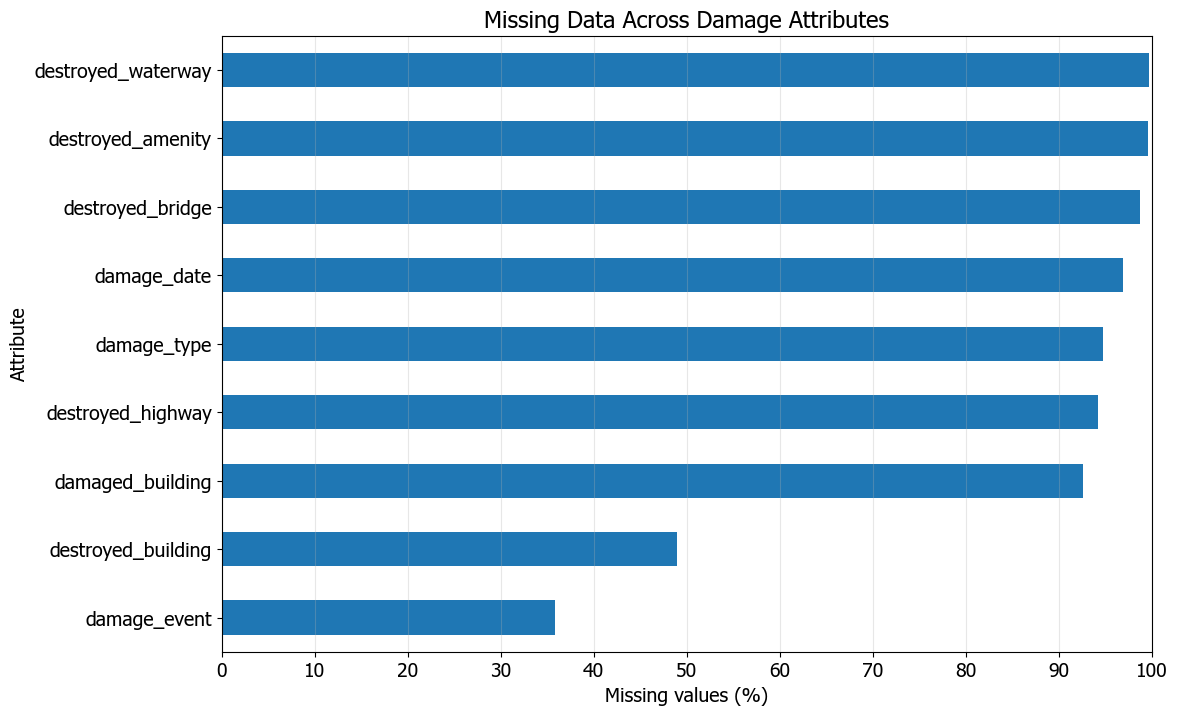

In [61]:
# missing percentage of data of destruction and damage caused by the floods(note: the graph does not conclude when did it occur)

plt.rc('font', family='Tahoma',size=14) 
missing_pct = df_mod[d_assessment_cols].isna().mean() * 100

missing_pct.sort_values().plot(
    kind='barh',
    figsize=(12, 8),
    xlabel='Missing values (%)',
    ylabel='Attribute',
    title='Missing Data Across Damage Attributes',
)
plt.xlim(0, 100)
plt.xticks(range(0, 101, 10))
plt.grid(axis='x', alpha=0.3)
plt.show()

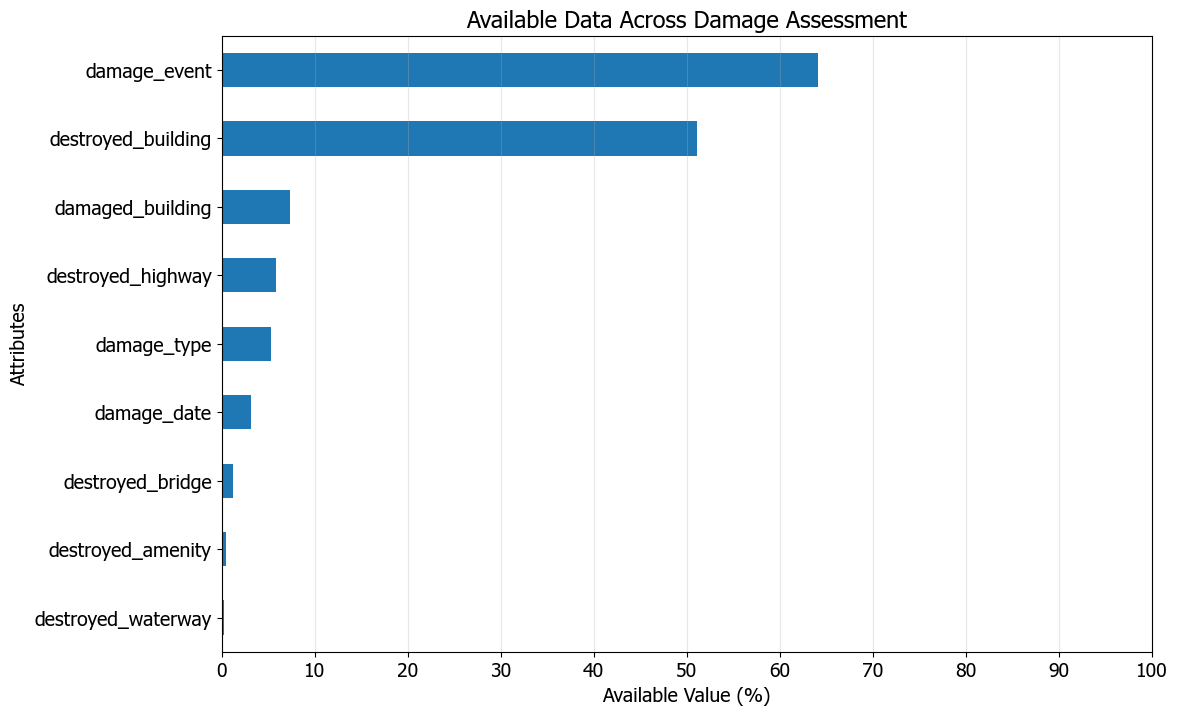

In [62]:
# available percentage of data of destruction and damage caused by the floods(note: the graph does not conclude when did it occur)

available_pct = df_mod[d_assessment_cols].notna().mean() * 100

available_pct.sort_values().plot(
    kind = 'barh',
    xlabel = 'Available Value (%)',
    ylabel = 'Attributes',
    figsize = (12,8),
    title = 'Available Data Across Damage Assessment'
    
)
plt.xlim(0, 100)
plt.xticks(range(0, 101, 10))
plt.grid(axis='x', alpha=0.3)
plt.show()

In [63]:
df_mod.groupby(
    ['damage_event','destroyed_building'],
    dropna = False
).size().reset_index(name = "incident_count",allow_duplicates=True)

,damage_event,destroyed_building,incident_count
0,2026NepalFlood,Apartments,12
1,2026NepalFlood,Government,2
2,2026NepalFlood,Hotel,6
3,2026NepalFlood,House,36
4,2026NepalFlood,Hut,2
5,2026NepalFlood,Industrial,4
6,2026NepalFlood,Retail,18
7,2026NepalFlood,School,6
8,2026NepalFlood,Yes,5390
9,2026NepalFlood,NaN,1758


In [64]:
df_mod.groupby(
    ['damage_event','destroyed_building',"source",],
    dropna = False
).size().reset_index(name = "incident_count",allow_duplicates=True)

,damage_event,destroyed_building,source,incident_count
0,2026NepalFlood,Apartments,http://www.mapillary.com/map/e/LJA_9J2t1rbBryO...,2
1,2026NepalFlood,Apartments,NaN,10
2,2026NepalFlood,Government,NaN,2
3,2026NepalFlood,Hotel,NaN,6
4,2026NepalFlood,House,NaN,36
5,2026NepalFlood,Hut,NaN,2
6,2026NepalFlood,Industrial,hydromaps_mapping,2
7,2026NepalFlood,Industrial,NaN,2
8,2026NepalFlood,Retail,NaN,18
9,2026NepalFlood,School,NaN,6


In [65]:
df_mod.groupby(
    ['organisation','action_taken','total_contributors','location','due_date','percent_mapped','percent_validated','creation_date','source'],
    dropna = False
).size().reset_index(name = 'incident_count',allow_duplicates=True)

,organisation,action_taken,total_contributors,location,due_date,percent_mapped,percent_validated,creation_date,source,incident_count
0,MAPBUDS,Added/Updated Buildings,145.0,NaN,2026-09-30,100.0,100.0,2026-08-29,NaN,2
1,MAPBUDS,Added/Updated Buildings,157.0,NaN,2026-09-30,100.0,100.0,2026-08-27,NaN,2
2,MAPBUDS,Added/Updated Residential Areas,59.0,NaN,2026-09-30,100.0,100.0,2026-09-01,NaN,2
3,MAPBUDS,Added/Updated Residential Areas,73.0,NaN,2026-09-30,100.0,100.0,2026-08-31,NaN,2
4,MAPBUDS,Added/Updated Roads,101.0,NaN,2026-09-30,100.0,100.0,2026-08-29,NaN,2
...,...,...,...,...,...,...,...,...,...,...
76,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,hydromaps_mapping,4
77,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,landsat,8
78,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,survey,22
79,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,www.geonames.org,2


In [66]:
df_mod.groupby(
    ['location','addr_street','municipality','priority','difficulty','population'],
    dropna = False
).size().reset_index(name='incident_count',allow_duplicates=True)

,location,addr_street,municipality,priority,difficulty,population,incident_count
0,0+520,NaN,NaN,NaN,NaN,NaN,2
1,13+260,NaN,NaN,NaN,NaN,NaN,2
2,2+520,NaN,NaN,NaN,NaN,NaN,2
3,27+220,NaN,NaN,NaN,NaN,NaN,2
4,27+840,NaN,NaN,NaN,NaN,NaN,2
...,...,...,...,...,...,...,...
76,NaN,NaN,Uttargaya,NaN,NaN,NaN,2
77,NaN,NaN,NaN,HIGH,Moderate,NaN,4
78,NaN,NaN,NaN,URGENT,Moderate,NaN,16
79,NaN,NaN,NaN,NaN,NaN,1500.0,2


In [67]:
# extracting to analyze the impact on bridges

bridge_col = []

for col in df_mod.columns:
    if col.startswith('bridge') or col.endswith('bridge'):
        bridge_col.append(col)

In [68]:
df_mod.groupby(
    bridge_col,
    dropna=False
).size().reset_index(name='incident_count')

,bridge,bridge_structure,destroyed_bridge,incident_count
0,Aqueduct,NaN,NaN,6
1,Viaduct,Arch,NaN,2
2,Viaduct,NaN,NaN,2
3,Yes,Beam,NaN,2
4,Yes,Simple Suspension,NaN,44
5,Yes,Suspension,NaN,8
6,Yes,NaN,NaN,262
7,NaN,NaN,Aqueduct,6
8,NaN,NaN,Viaduct,2
9,NaN,NaN,Yes,130


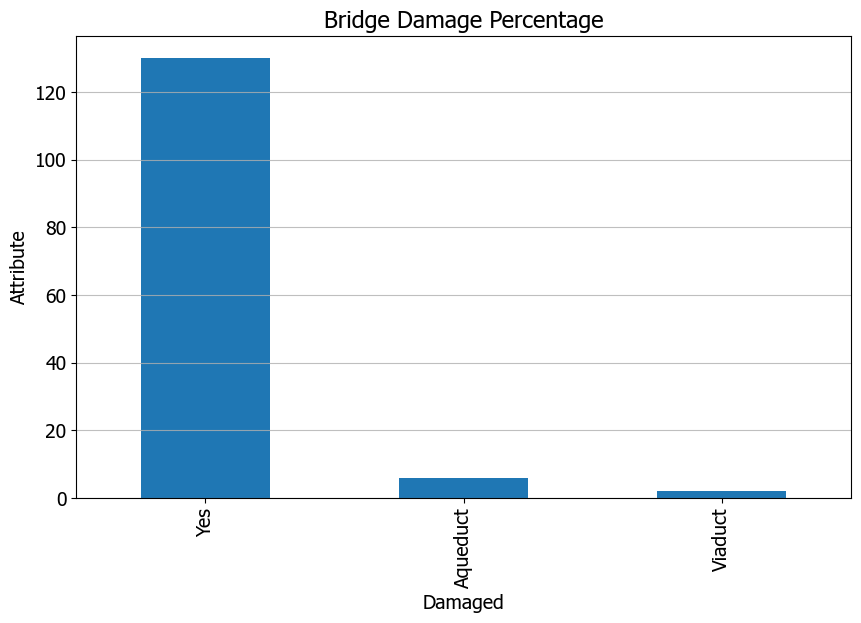

In [69]:
bridge_damage_pct = df_mod[bridge_col].notna().mean() * 100 # percentage of damaged bridges from the grouped data above

plt.rc('font', family='Tahoma',size=14) 

df_mod['destroyed_bridge'].value_counts().plot(
    figsize = (10,6),
    kind = 'bar',
    xlabel= 'Damaged',
    ylabel = 'Attribute',
    title = 'Bridge Damage Percentage'
)
plt.grid(axis = 'y',alpha=0.8)

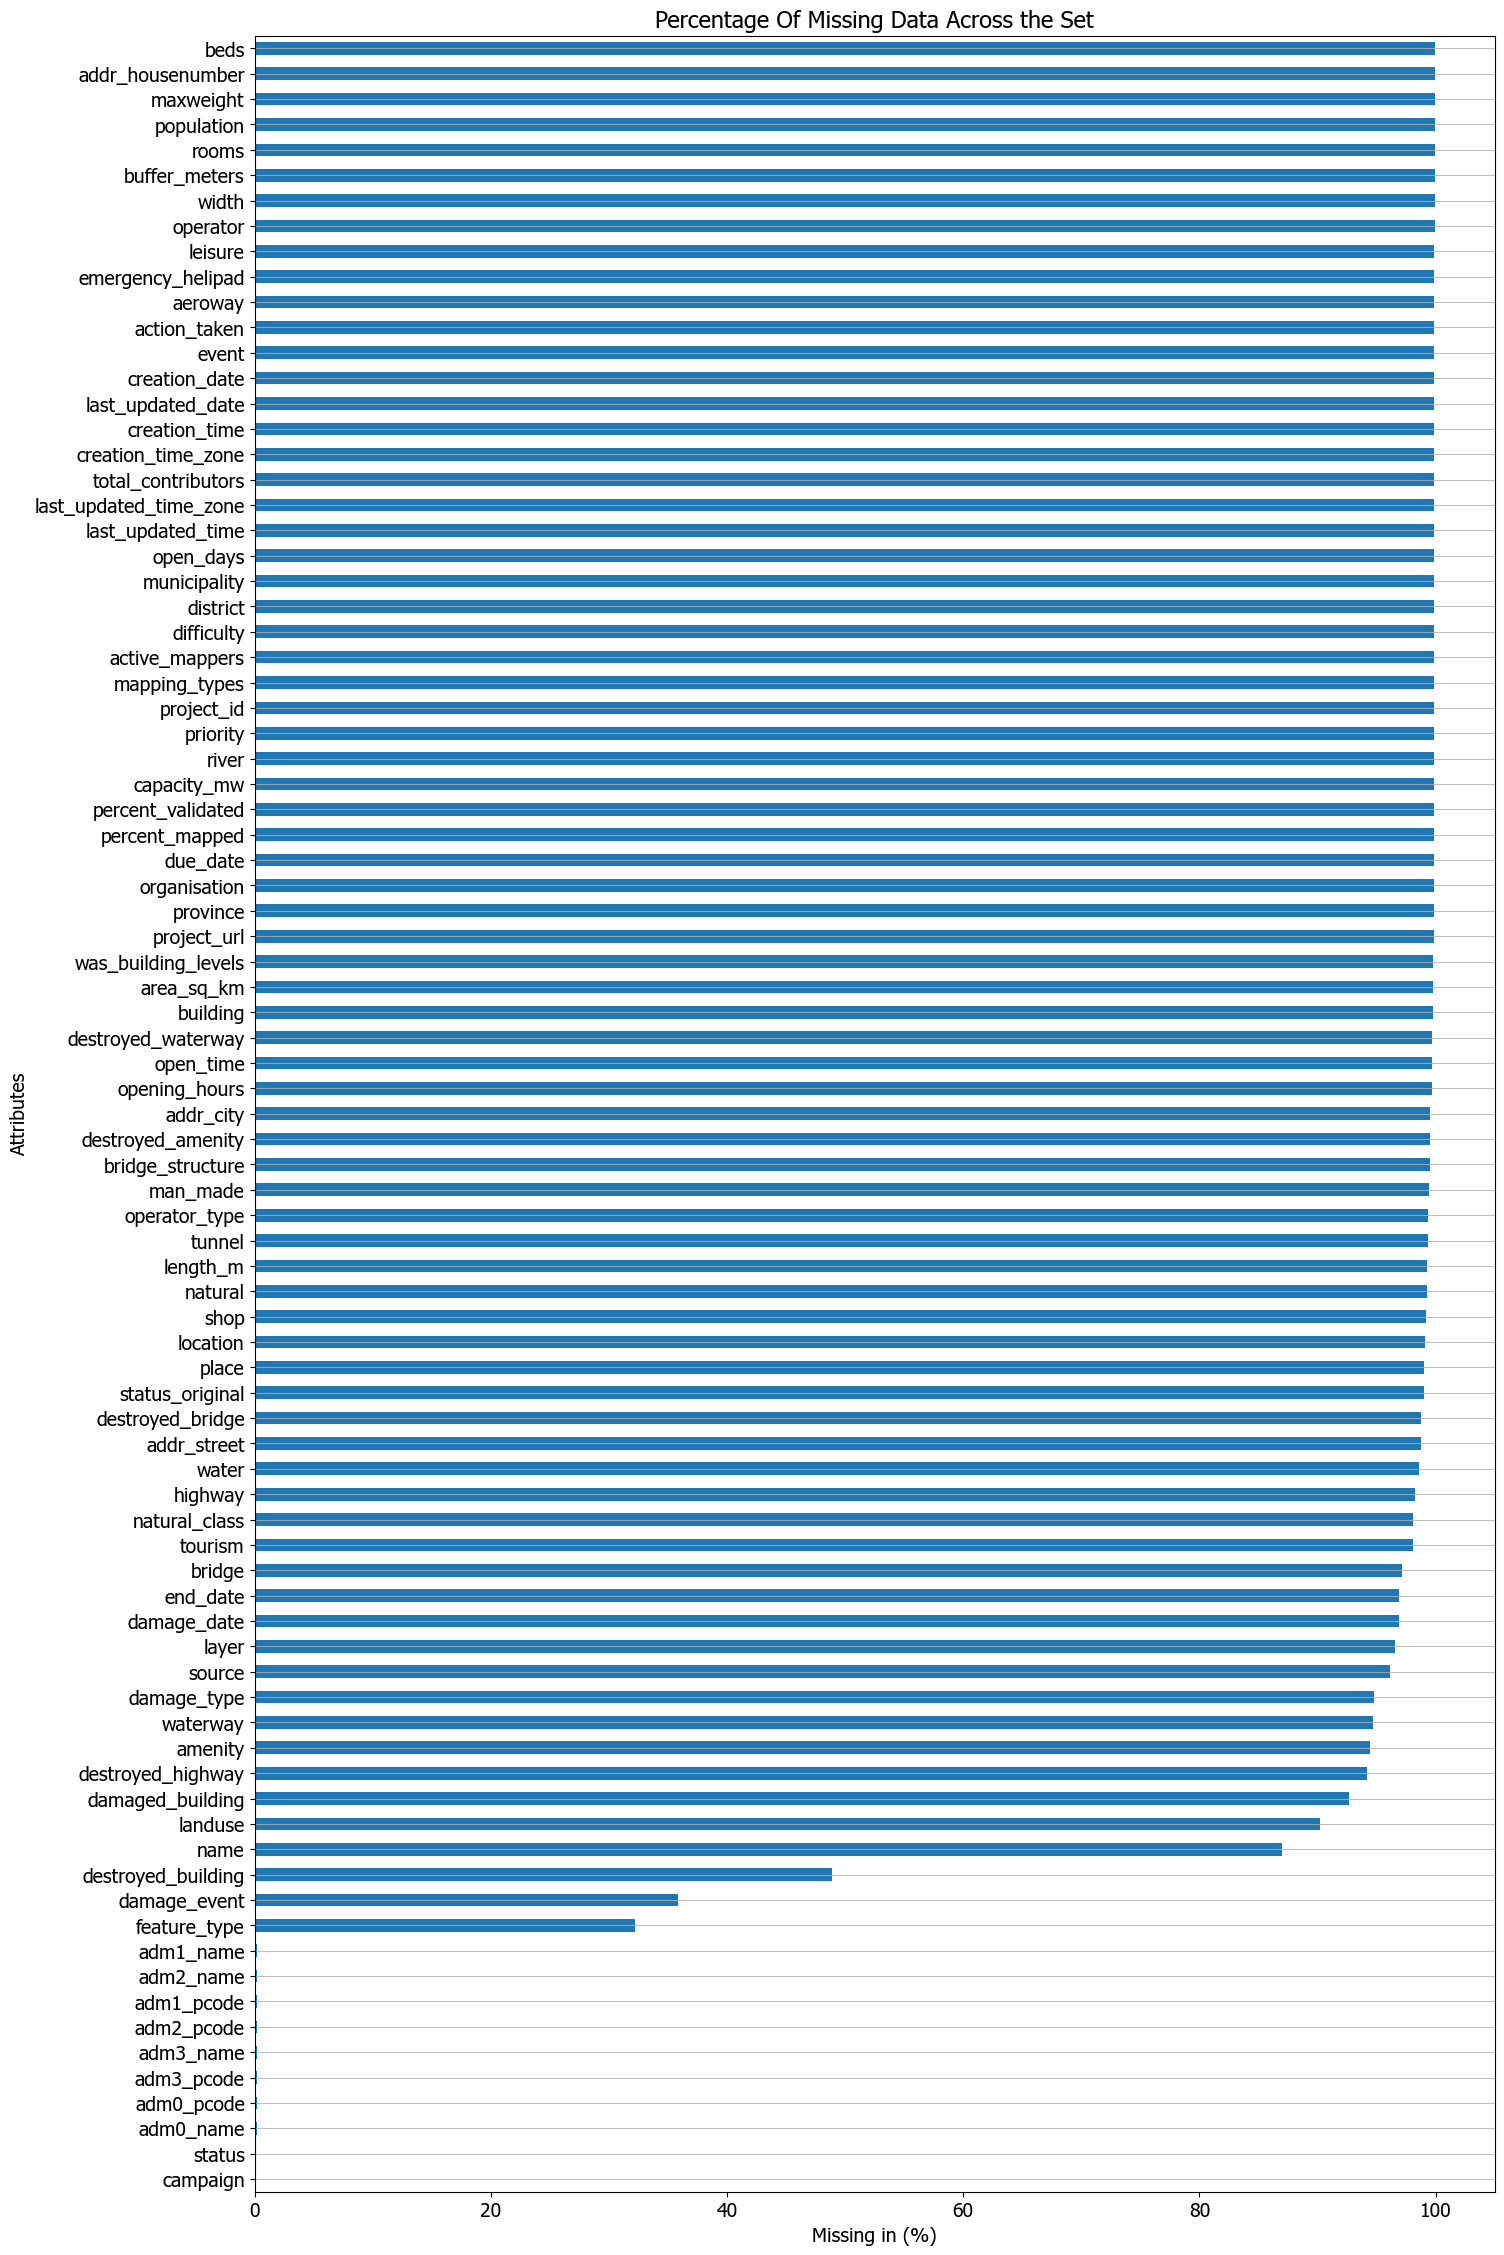

In [70]:
# percentage of missing data across the data set

plt.rc('font',family = "Tahoma")

all_missing_pct = df_mod.isna().mean() * 100

all_missing_pct.sort_values().plot(
    kind = 'barh',
    figsize = (16,28),
    title = 'Percentage Of Missing Data Across the Set',
    xlabel = 'Missing in (%)',
    ylabel = 'Attributes'
)
plt.grid(alpha = 0.8,axis='y')


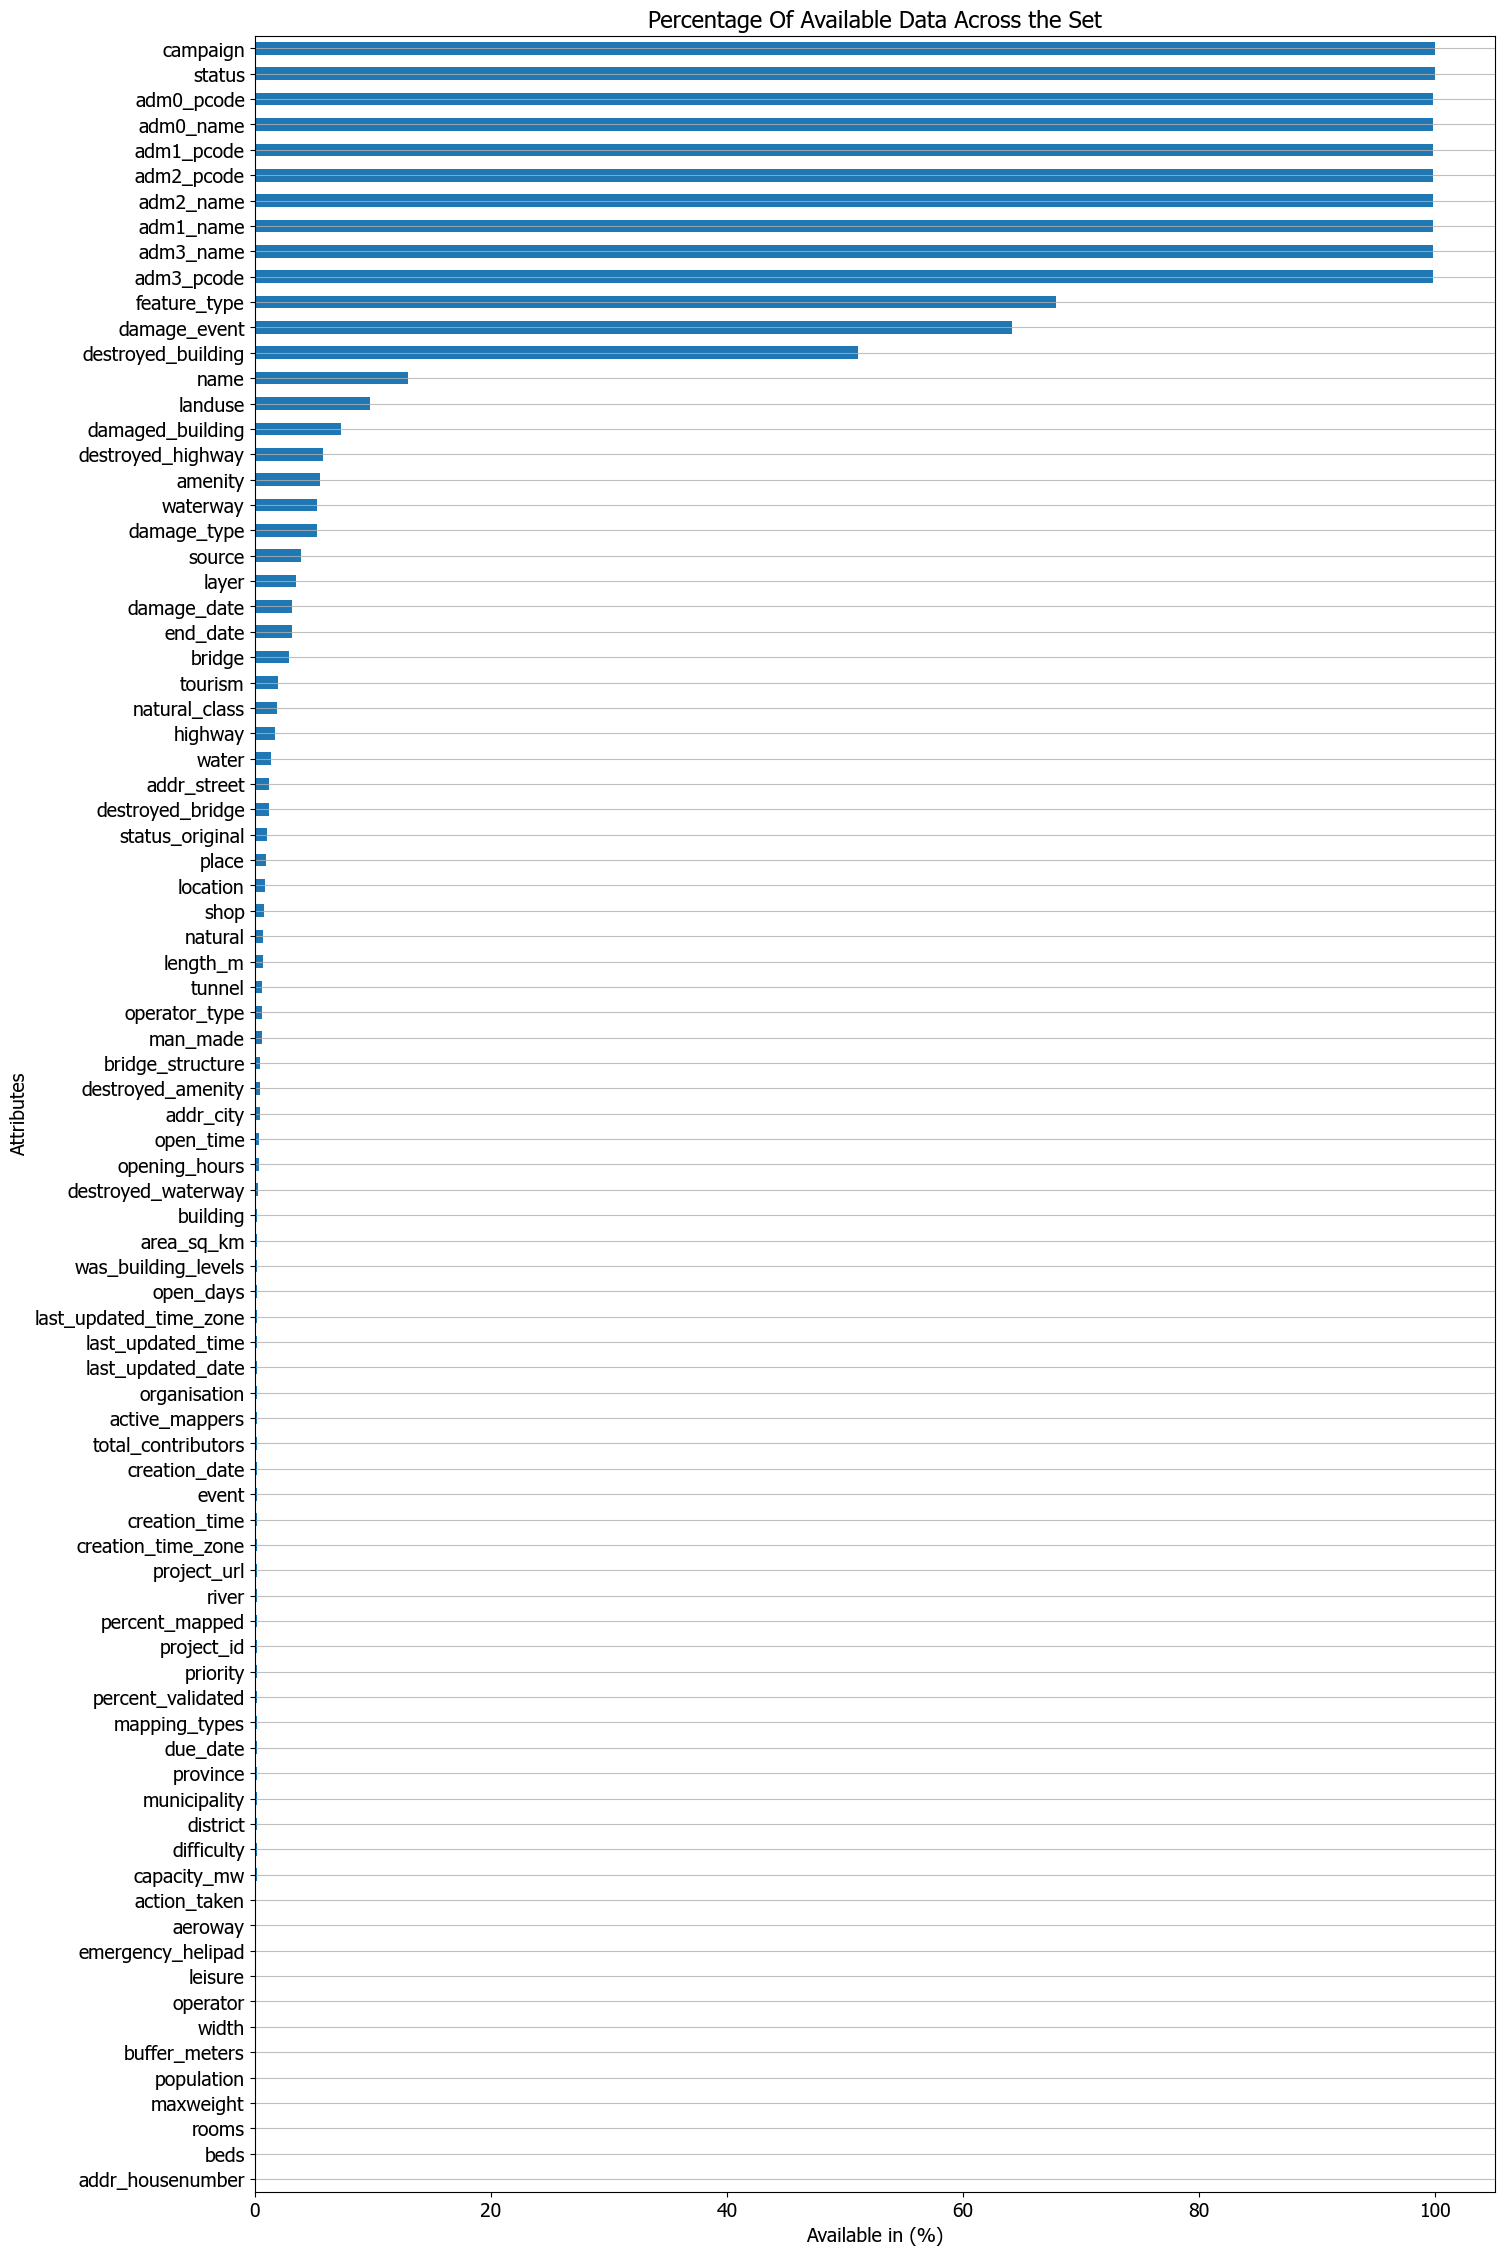

In [71]:
# percentage of missing data across the data set

plt.rc('font',family = "Tahoma")

non_missing_pct = df_mod.notna().mean() * 100

non_missing_pct.sort_values().plot(
    kind = 'barh',
    figsize = (16,28),
    title = 'Percentage Of Available Data Across the Set',
    xlabel = 'Available in (%)',
    ylabel = 'Attributes'
)
plt.grid(alpha = 0.8,axis='y')


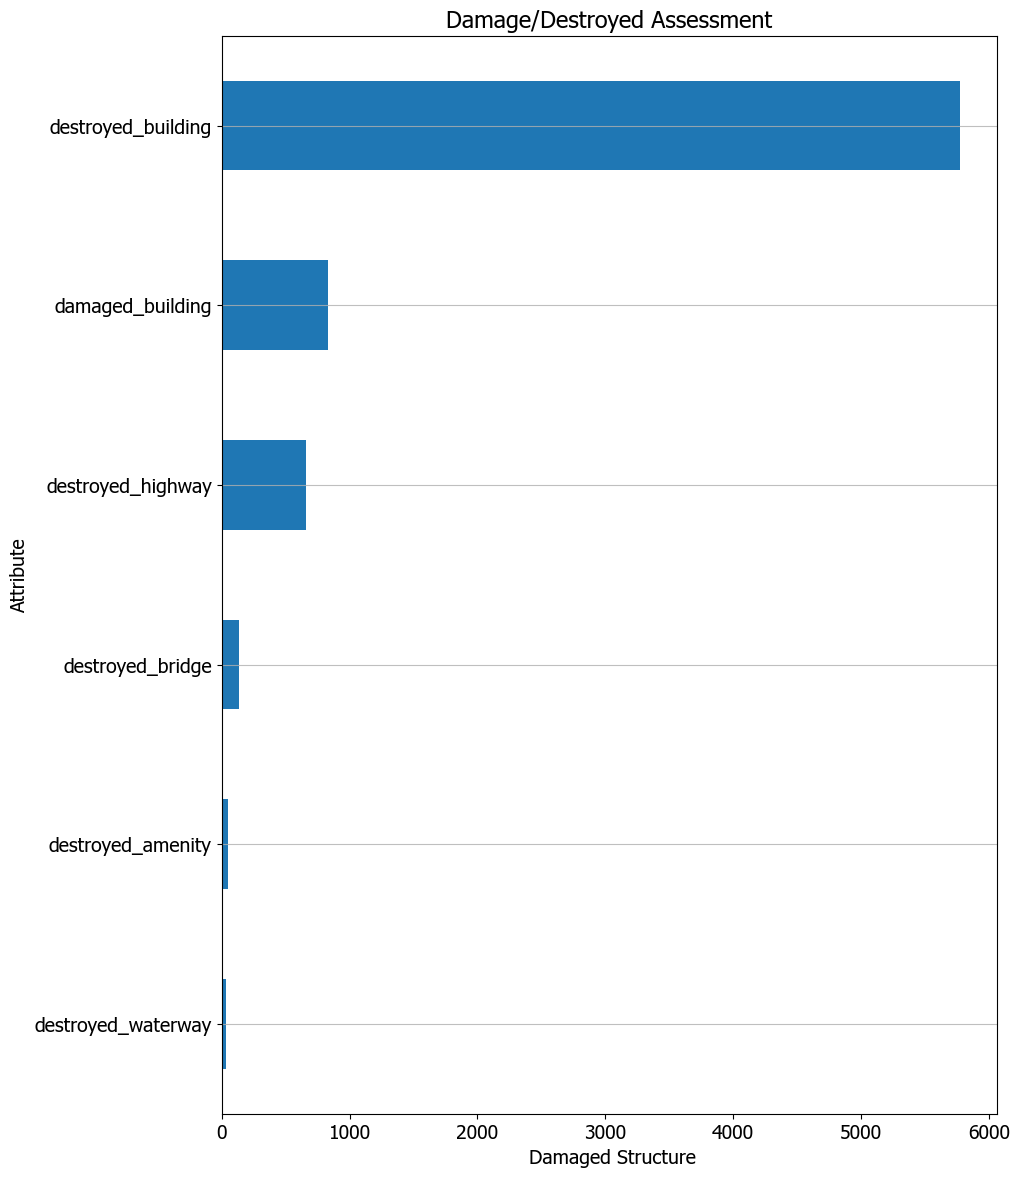

In [72]:
# number of buildings damage/destroyed graph
req_assessment = ['damaged_building','destroyed_amenity','destroyed_bridge','destroyed_building','destroyed_highway','destroyed_waterway']
df_mod[req_assessment].notna().sum().sort_values().plot(
    kind = 'barh',
    figsize= (10,14),
    xlabel= ' Damaged Structure',
    ylabel = 'Attribute',
    title = 'Damage/Destroyed Assessment'
)
plt.grid(alpha = 0.8,axis='y')


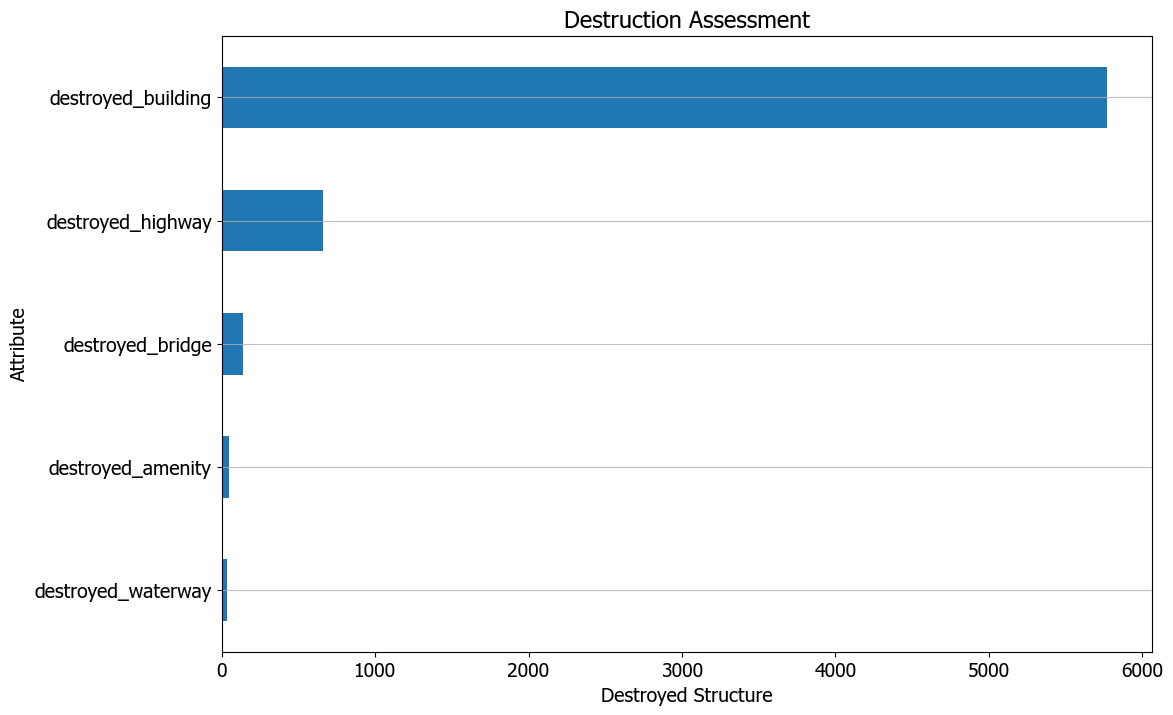

In [73]:
df_mod[des_cols].notna().sum().sort_values().plot(
    kind = 'barh',
    figsize = (12,8),
    xlabel = 'Destroyed Structure',
    ylabel = 'Attribute',
    title= 'Destruction Assessment'
)
plt.grid(alpha=0.8,axis='y')

<Axes: title={'center': 'Building Recorded in Destroyed Attribute'}, xlabel='Number of Records', ylabel='Recorded Building Category'>

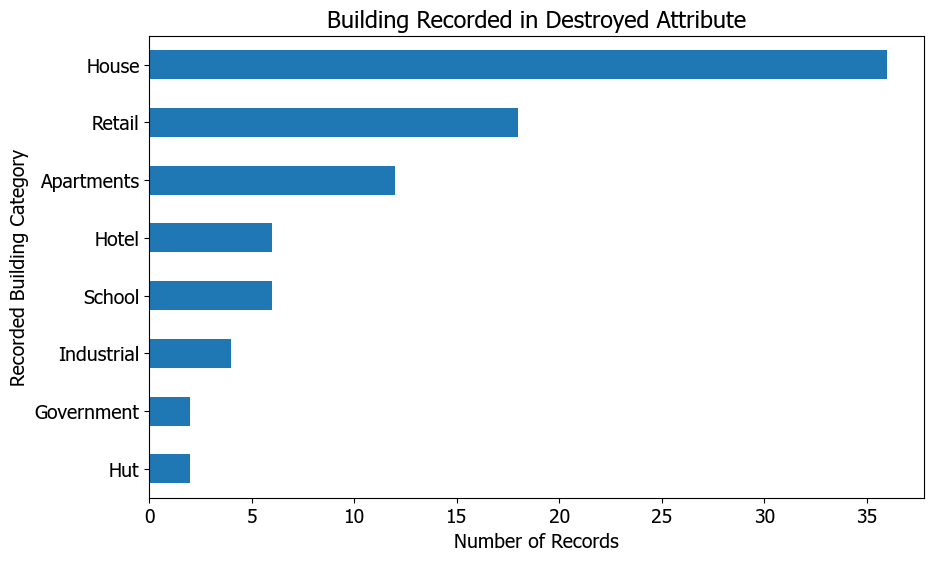

In [74]:
# types of building destroyed (not enough data to conclude if the flood of 2026 destroyed the structures)
# dropping 'yes' from data as we cannot explicitly say what exactly was destroyed in the current analysis

building_types = [
    'House', 'Retail', 'Apartments', 'School',
    'Hotel', 'Industrial', 'Hut', 'Government'
]

building_counts = (
    df_mod['destroyed_building']
    .value_counts()
    .reindex(building_types)
    .dropna()
    .sort_values()
)

building_counts.plot(
    kind='barh',
    figsize=(10, 6),
    xlabel='Number of Records',
    ylabel='Recorded Building Category',
    title='Building Recorded in Destroyed Attribute'
)

In [75]:
# water way and water bodies graph 
water_cols = ['destroyed_waterway'] # added in advance 

for col in df_mod.columns:
    if col.startswith('water') or col.endswith('water'):
        water_cols.append(col)
        
print(water_cols)

['destroyed_waterway', 'water', 'waterway']


In [76]:
df_mod.groupby(
    water_cols,
    dropna=False
).size().reset_index(name = "occurrence")

# Only 748 of 11,302 records have at least one of those attributes and the values are sparse and some appear truncated.

,destroyed_waterway,water,waterway,occurrence
0,Canal,NaN,NaN,14
1,Dam,NaN,NaN,4
2,Weir,NaN,NaN,14
3,NaN,Basin,Check Da,10
4,NaN,Canal,Check Da,2
5,NaN,Pond,NaN,18
6,NaN,Reservoir,NaN,22
7,NaN,River,NaN,108
8,NaN,NaN,Canal,78
9,NaN,NaN,Check Da,2


In [77]:
df_mod.groupby(
    [df_mod['amenity'],df_mod['status']],
    dropna=False
).size().reset_index(name = 'occurrence')

,amenity,status,occurrence
0,Atm,Destroyed,8
1,Atm,Standing,4
2,Bank,Destroyed,8
3,Bank,Standing,96
4,Bus Station,Destroyed,4
5,Bus Station,Standing,8
6,Cafe,Destroyed,2
7,Cafe,Standing,10
8,Charging Station,Standing,4
9,Clinic,Standing,4


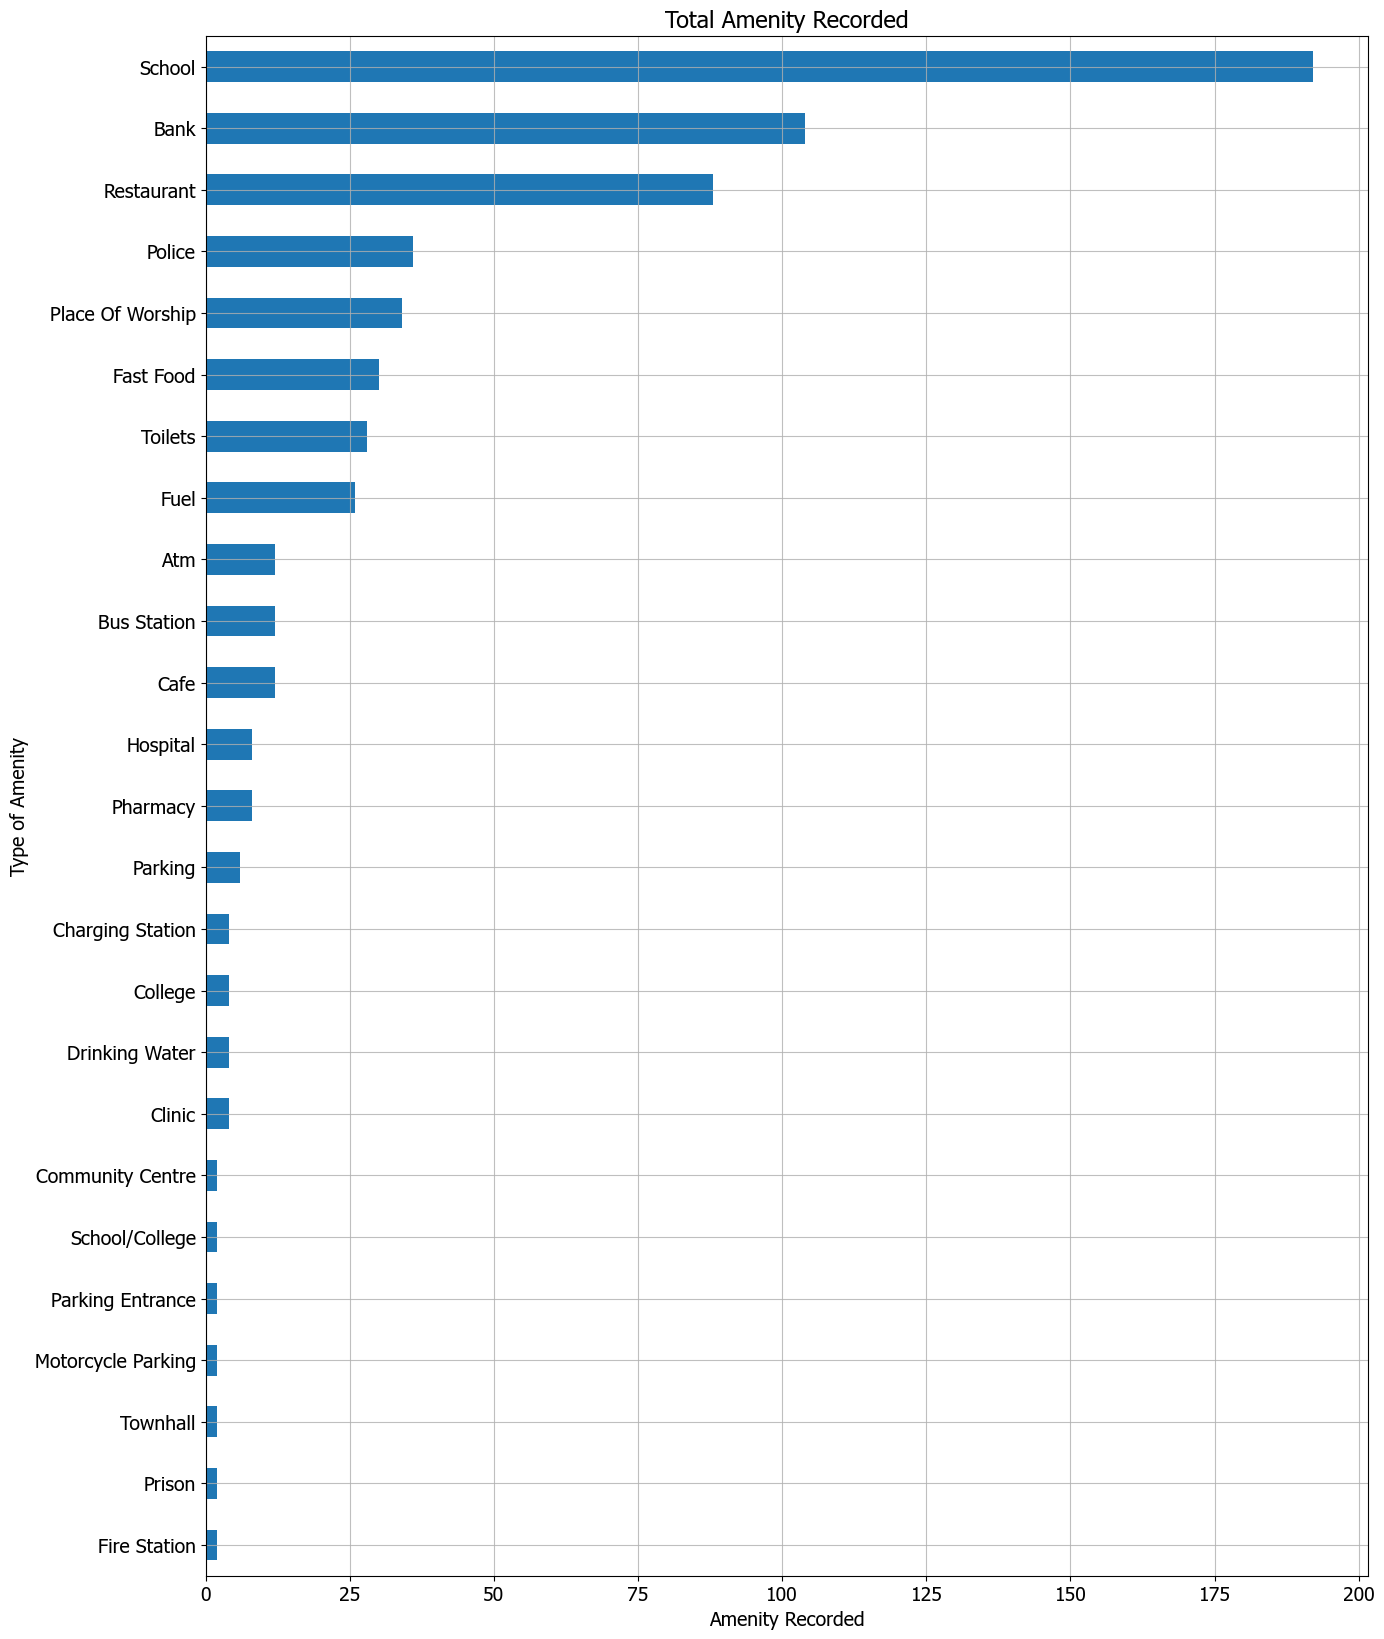

In [78]:
# status graph for amenity

df_mod['amenity'].value_counts(dropna=True).sort_values().plot(
    figsize=(15,20),
    kind = 'barh',
    xlabel='Amenity Recorded',
    ylabel='Type of Amenity',
    title='Total Amenity Recorded'
)
plt.grid(alpha=0.8)

In [ ]:
# includes unique project id's and respective url's
df_mod[['project_id','project_url']].dropna().drop_duplicates()